<center>
  <img src="https://upload.wikimedia.org/wikipedia/commons/6/68/Logo_FPT_Education.png" width="300" alt="FPT Education logo"  />
</center>

# ADY201m - AI, DATA SCIENCE WITH PYTHON & SQL
### REPORT 2 (ONGOING ASSESSMENT 2)
**Topic:** Exploratory Data Analysis (EDA), Feature Engineering & Model Building / Evaluation

---

### PROJECT INFORMATION
- **Project Title:** The Five Factor Model of personality and evaluation of drug consumption risk
- **Class Code:** AI2104
- **Group Name/ID:** Group 7
- **Member List:**
  1. Hoàng Trọng Hiếu - HE211206
  2. Nguyễn Quang Minh - HE211213
  3. Nguyễn Thái Bình Dương - HE211161
  4. Ngô Anh Duy - HE211165
- **Dataset Source Link:** https://archive.ics.uci.edu/dataset/373/drug+consumption+quantified
- **Submission Date:** [Format DD/MM/YYYY]

---

## GRADING RUBRIC

*(This section is reserved for the instructor to grade and evaluate student work)*

| Criteria | Assessment Content | Max Score | Score Achieved | Lecturer's Feedback |
| :--- | :--- | :---: | :---: | :--- |
| **1. Exploratory Data Analysis (EDA)** | Univariate, bivariate & multivariate analysis, visualization, and meaningful business insights. | **3.0 pts** | | |
| **2. Feature Engineering & Preparation** | Proper categorical encoding, feature scaling, feature selection/creation, and train-test split. | **3.0 pts** | | |
| **3. Model Building & Evaluation** | Implementation of baseline & advanced models, performance metric evaluation, and model comparison. | **3.0 pts** | | |
| **4. Discussion & Conclusion** | Clear business interpretation of results, actionable recommendations, and next steps. | **1.0 pt** | | |
| **TOTAL SCORE** | **Overall evaluation of Report 2 execution** | **10.0 pts** | | |

---

# PART 1: EXPLORATORY DATA ANALYSIS (EDA) [3.0 POINTS]

### Key Guidelines:
1. **Univariate Analysis:** Visualize and describe the distribution of the target variable and key features.
2. **Bivariate / Multivariate Analysis:** Explore relationships between predictor variables and the target variable.
3. **Correlation Analysis:** Generate a correlation heatmap and extract top insights.

---

#### STUDENT TASK 1.1: UNIVARIATE ANALYSIS
*Write Python code to plot distributions (histograms, countplots, boxplots) for the target variable and key numerical/categorical features.*

User
0    964
1    921
Name: count, dtype: int64


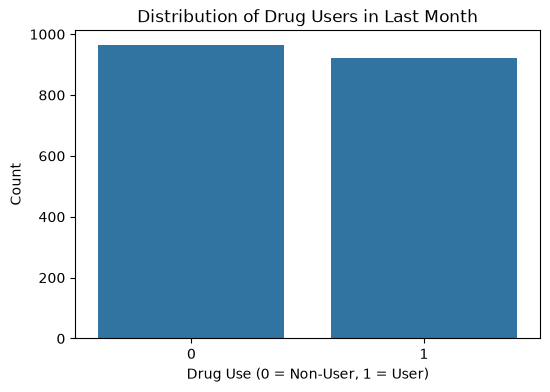

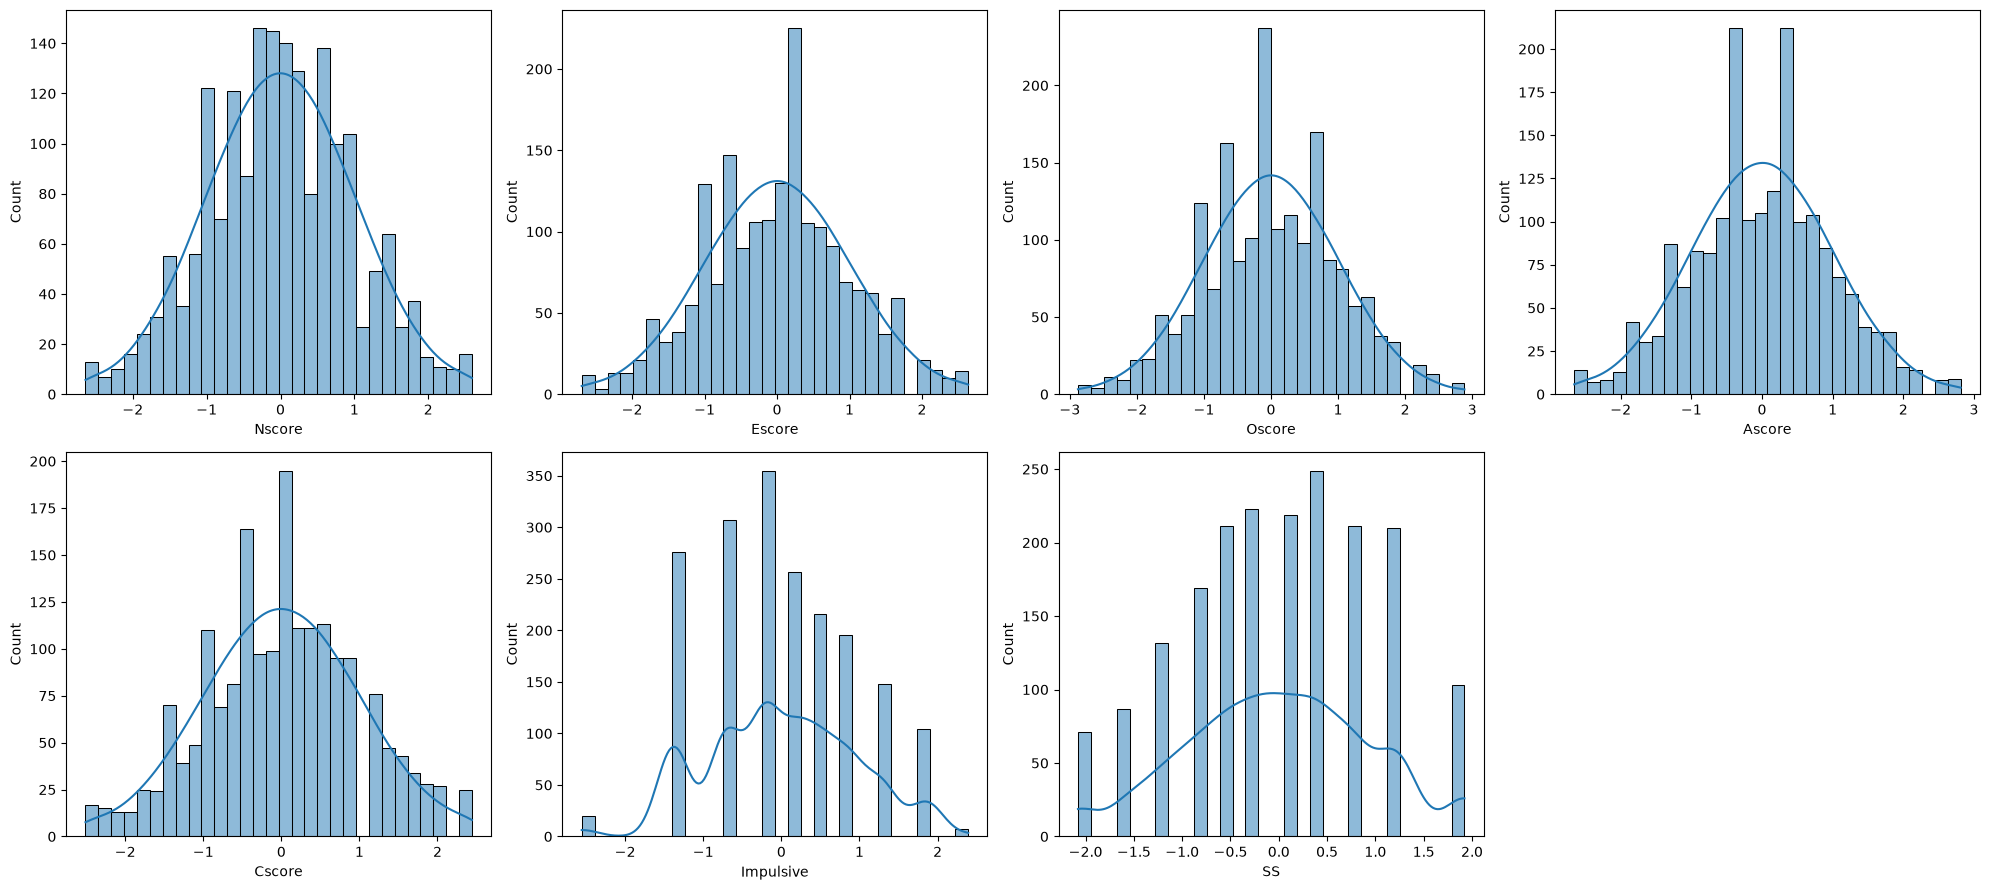


Checking if mapping goes wrong or not: 0



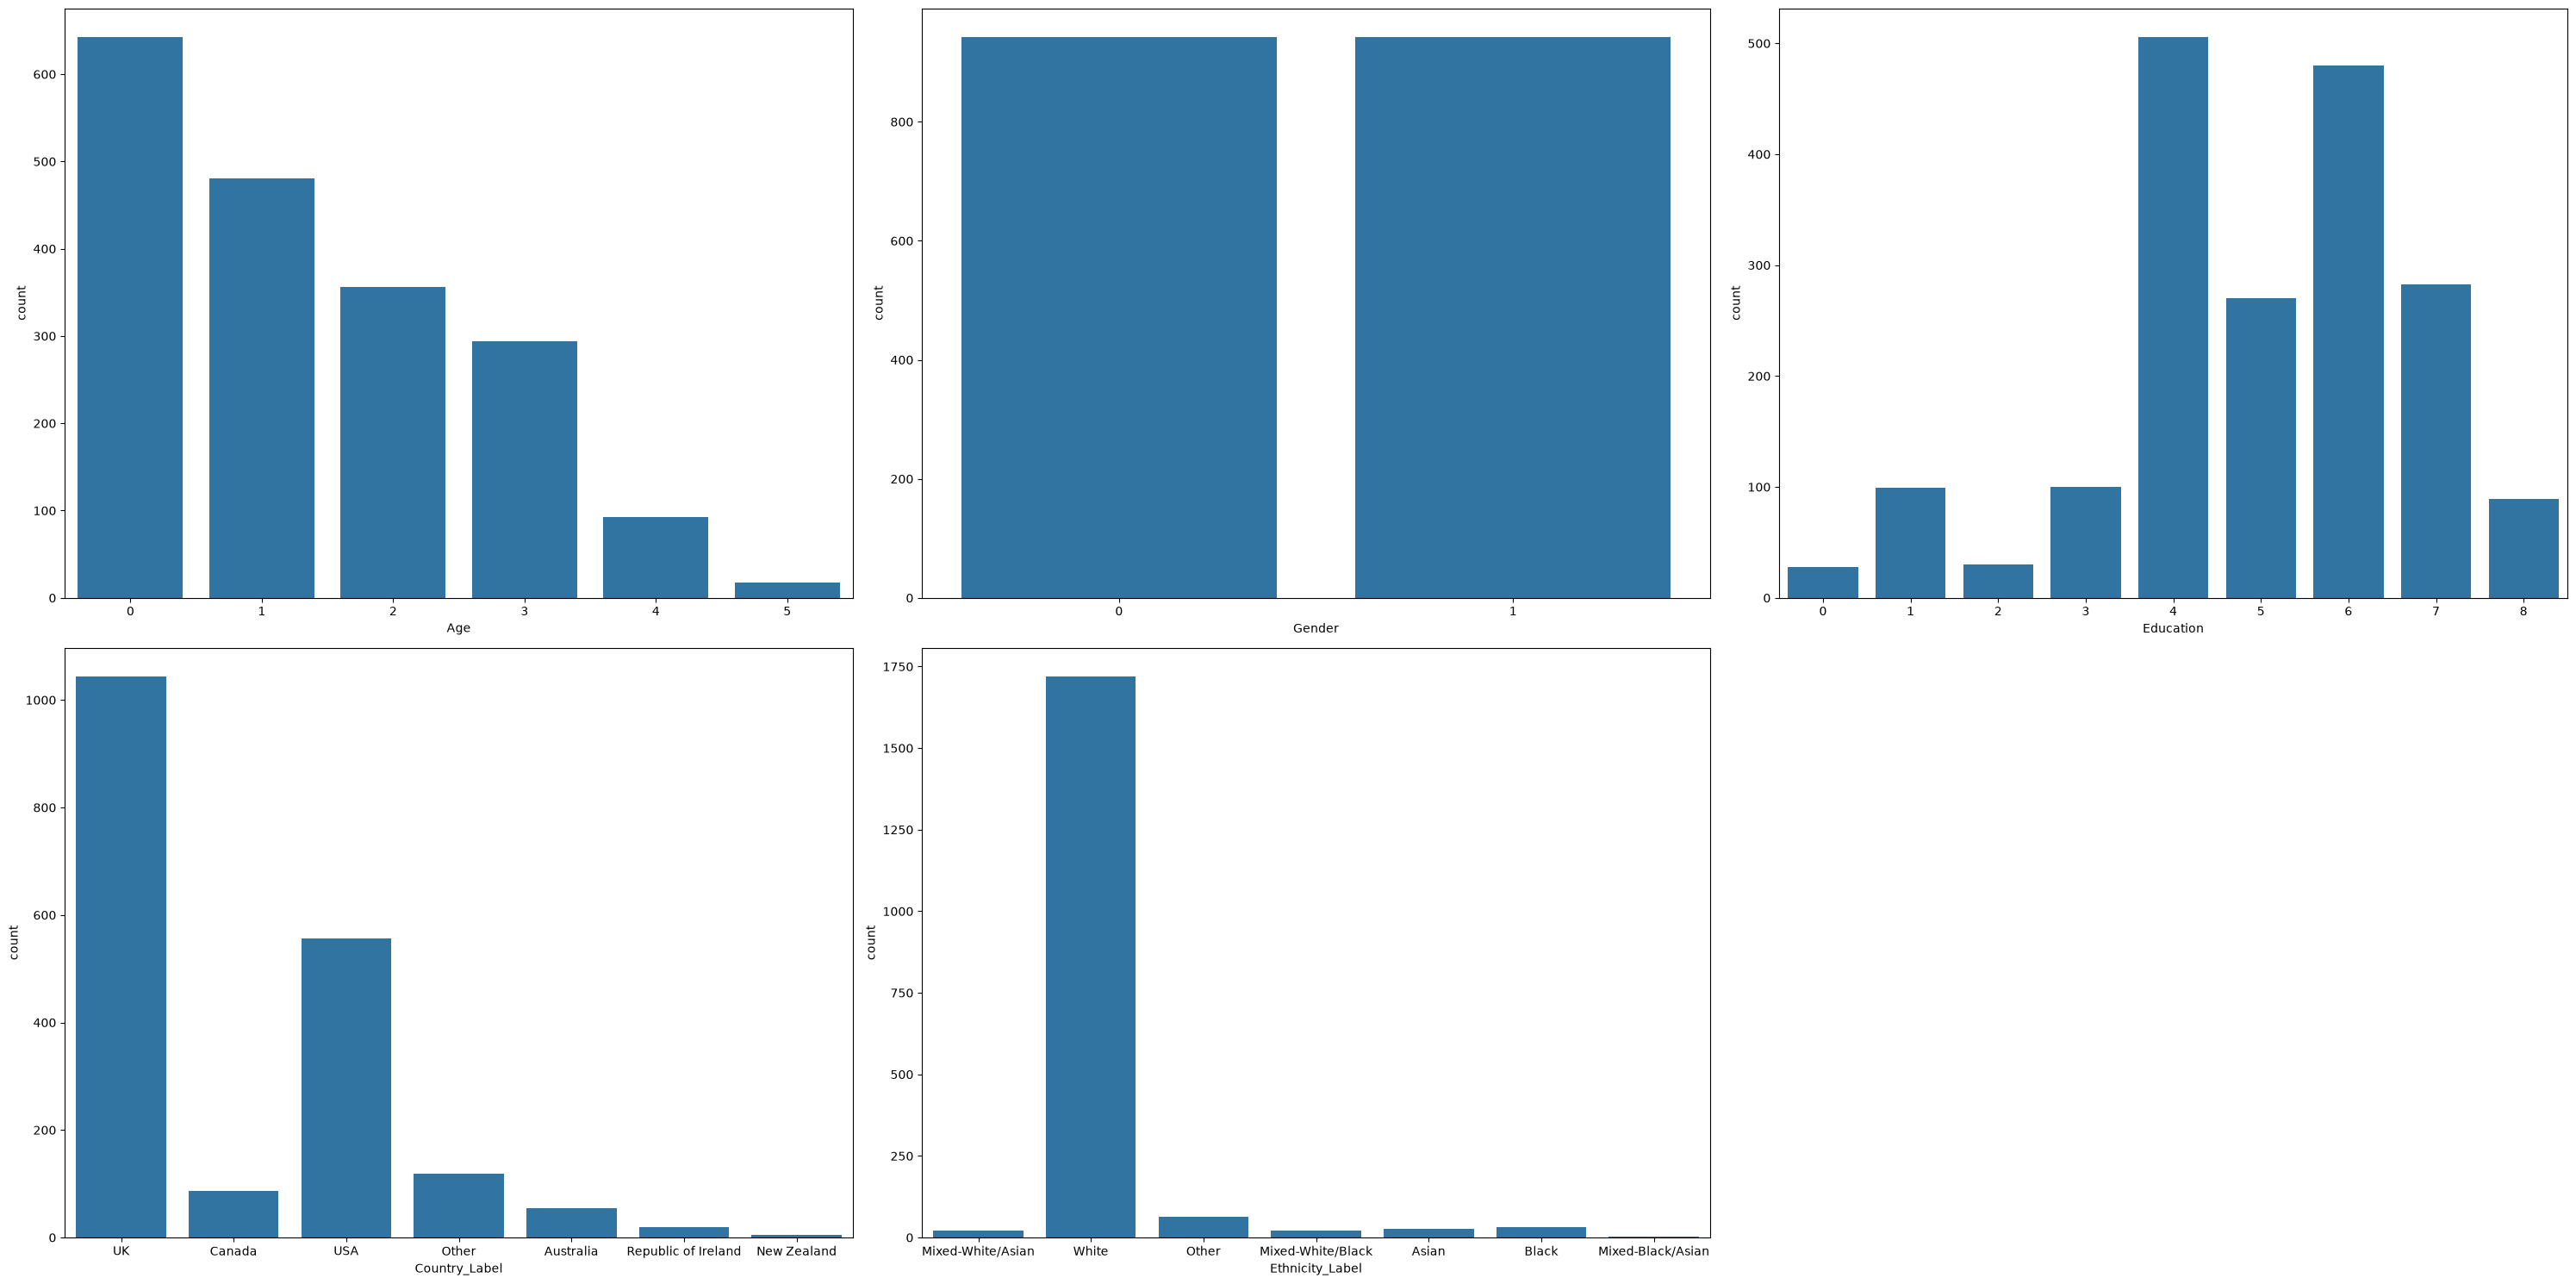

(2, 0, 5, 0.96082, 0.126, '0', '0', '0', '0', '0', '0', '0', '0')
(1, 1, 8, 0.96082, -0.31685, '0', '1', '0', '0', '0', '0', '0', '1')
(2, 1, 5, 0.96082, -0.31685, '0', '0', '0', '0', '0', '0', '0', '0')
(0, 0, 7, 0.96082, -0.31685, '0', '0', '0', '0', '0', '0', '0', '0')
(2, 0, 8, 0.96082, -0.31685, '0', '0', '0', '0', '0', '0', '0', '0')


In [ ]:
# TODO: [STUDENTS FILL IN CODE HERE]
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the cleaned dataset from Report 1
df = pd.read_csv('cleaned_dataset_report1.csv')

# 2. Create Target Column (User)
drug_columns = [
    'Amphet', 'Cannabis', 'Coke', 'Ketamine',
    'LSD', 'Mushrooms', 'Legalh', 'Ecstasy'
]

# 1 = Used at least one drug in the last month
# 0 = Did not use any drug in the last month
df['User'] = (df[drug_columns] == 1).any(axis=1).astype(np.int8)
print(df['User'].value_counts())

# 3. Distribution of Target Variable
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="User")
plt.title('Distribution of Drug Users in Last Month')
plt.xlabel('Drug Use (0 = Non-User, 1 = User)')
plt.ylabel('Count')
plt.show()

# 4. Distribution of Numerical Features
numerical_features = df[[
    'Nscore', 'Escore', 'Oscore',
    'Ascore', 'Cscore', 'Impulsive', 'SS'
]]

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.flatten()

for i, col in enumerate(numerical_features.columns):
  sns.histplot(data=numerical_features, x = col, bins=30, kde=True, ax=axes[i])

for i in range(7, len(axes)):
  fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

# 5. Distribution of Categorical Features
mapping = {
  "Country": {
    -0.09765: 'Australia',
     0.24923: 'Canada',
    -0.46841: 'New Zealand',
    -0.28519: 'Other',
     0.21128: 'Republic of Ireland',
     0.96082: 'UK',
    -0.57009: 'USA'
  },
  "Ethnicity": {
    -0.50212: 'Asian',
    -1.10702: 'Black',
     1.90725: 'Mixed-Black/Asian',
     0.12600: 'Mixed-White/Asian',
    -0.22166: 'Mixed-White/Black',
     0.11440: 'Other',
    -0.31685: 'White'
  }
}

df['Country_Label'] = df['Country'].map(lambda x: mapping["Country"].get(x, np.nan))
df['Ethnicity_Label'] = df['Ethnicity'].map(lambda x: mapping["Ethnicity"].get(x, np.nan))
print(f"\nChecking if mapping goes wrong or not: {df.isna().sum(axis=0).sum()}\n")

categorical_features = df[[
    'Age', 'Gender', 'Education', 'Country_Label', 'Ethnicity_Label'
]]

fig, axes = plt.subplots(2, 3, figsize=(30, 15))
axes = axes.flatten()
for i, col in enumerate(categorical_features.columns):
  sns.countplot(data=categorical_features, ax=axes[i], x=col)

for i in range(5, 6):
  fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

#6 sql setup 
import sqlite3
import csv 

conn = sqlite3.connect(":memory:")
cursor = conn.cursor()

#table 
cursor.execute("""
CREATE TABLE drug_data (
      Age INTEGER, 
      Gender INTEGER,
      Education INTEGER, 
      Country REAL, 
      Ethnicity REAL, 
      Amphet TEXT,
      Cannabis TEXT, 
      Coke TEXT,
      Ketamine TEXT,
      LSD TEXT,
      Mushrooms TEXT,
      Legalh TEXT, 
      Ecstasy TEXT
)
""")

with open(".\\cleaned_dataset_report1.csv", newline="", encoding="utf-8-sig") as file:
  rows = csv.DictReader(file)

  for row in rows:
    cursor.execute("""
        INSERT INTO drug_data VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)
""", (
    int(row["Age"]),
    int(row["Gender"]),
    int(row["Education"]),
    float(row["Country"].replace(" ", "")),
    float(row["Ethnicity"]), 
    row["Amphet"],
    row["Cannabis"],
    row["Coke"],
    row["Ketamine"],
    row["LSD"],
    row["Mushrooms"],
    row["Legalh"],
    row["Ecstasy"]
))
conn.commit()
cursor.execute("SELECT * FROM drug_data LIMIT 5")

for row in cursor.fetchall():
    print(row)

In [5]:
country_query = """
WITH labeled_country  AS (
    SELECT CASE ROUND(Country, 5)
        WHEN -0.09765 THEN 'Australia'
        WHEN  0.24923 THEN 'Canada'
        WHEN -0.46841 THEN 'New Zealand'
        WHEN -0.28519 THEN 'Other'
        WHEN  0.21128 THEN 'Republic of Ireland'
        WHEN  0.96082 THEN 'UK'
        WHEN -0.57009 THEN 'USA'
    END AS Country_Label
    FROM drug_data
)
SELECT 
  Country_label AS Country,
  COUNT(*) AS Count,
  ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM drug_data), 2) AS "Relative Frequency (%)"
FROM labeled_country
WHERE Country_Label IS NOT NULL 
GROUP BY Country_Label 
ORDER BY Count DESC;
"""

cursor.execute(country_query)
print(f"{'Country':<25} {'Count':>8} {'Relative Frequency (%)':>25}")
record = cursor.fetchall()
for country, count, percentage in record:
    print(f"{country:<25} {count:>8} {percentage:>25}")

Country                      Count    Relative Frequency (%)
UK                            1044                     55.38
USA                            557                     29.55
Other                          118                      6.26
Canada                          87                      4.62
Australia                       54                      2.86
Republic of Ireland             20                      1.06
New Zealand                      5                      0.27


In [6]:
ethnicity_query = """
WITH labeled_ethnicity AS (
    SELECT CASE ROUND(Ethnicity, 5)
        WHEN -0.50212 THEN 'Asian'
        WHEN -1.10702 THEN 'Black'
        WHEN  1.90725 THEN 'Mixed-Black/Asian'
        WHEN  0.12600 THEN 'Mixed-White/Asian'
        WHEN -0.22166 THEN 'Mixed-White/Black'
        WHEN  0.11440 THEN 'Other'
        WHEN -0.31685 THEN 'White'
    END AS Ethnicity_Label
    FROM drug_data
)
SELECT
    Ethnicity_Label AS Ethnicity,
    COUNT(*) AS Count,
    ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM drug_data), 2)
        AS "Relative Frequency (%)"
FROM labeled_ethnicity
WHERE Ethnicity_Label IS NOT NULL
GROUP BY Ethnicity_Label
ORDER BY Count DESC;
"""

cursor.execute(ethnicity_query)
record = cursor.fetchall()

print(f"{'Ethnicity':<25} {'Count':>8} {'Relative Frequency (%)':>25}")
for ethnicity, count, percentage in record:
    print(f"{ethnicity:<25} {count:>8} {percentage:>25.2f}")

Ethnicity                    Count    Relative Frequency (%)
White                         1720                     91.25
Other                           63                      3.34
Black                           33                      1.75
Asian                           26                      1.38
Mixed-White/Black               20                      1.06
Mixed-White/Asian               20                      1.06
Mixed-Black/Asian                3                      0.16


### Nhận xét về sự mất cân bằng của Country và Ethnicity

**Country:**

- Trong tổng số 1.885 quan sát, UK chiếm 55,38% (1.044 quan sát) và USA chiếm 29,55% (557 quan sát). Như vậy, hai quốc gia này chiếm tổng cộng **84,93%** tập dữ liệu.
- Ngược lại, New Zealand chỉ có 5 quan sát (0,27%) và Republic of Ireland có 20 quan sát (1,06%).
- Sự chênh lệch đáng kể về số lượng quan sát giữa các quốc gia cho thấy dữ liệu có tính đại diện địa lý hạn chế. Việc sử dụng Country làm đặc trưng dự đoán có thể khiến mô hình học chủ yếu những mối quan hệ đặc trưng cho UK và USA, trong khi các nhóm quốc gia ít được đại diện không có đủ quan sát để mô hình học các mẫu đáng tin cậy.

**Ethnicity:**

- Phân phối của Ethnicity mất cân bằng nghiêm trọng, khi nhóm White chiếm **91,25%** (1.720 quan sát), trong khi sáu nhóm còn lại chỉ chiếm tổng cộng 8,75% (165 quan sát).
- Đặc biệt, nhóm Mixed-Black/Asian chỉ có 3 quan sát (0,16%). Kích thước mẫu quá nhỏ của một số nhóm có thể làm tăng độ bất định trong quá trình học và nguy cơ overfitting đối với các nhóm ít được đại diện.

**Kết luận và quyết định Feature Selection:**

Dựa trên kết quả EDA, nhóm quyết định loại bỏ hai đặc trưng `Country` và `Ethnicity` khỏi tập dữ liệu đầu vào nhằm:

- Hạn chế sự phụ thuộc trực tiếp của mô hình vào các đặc trưng nhân khẩu học có phân phối mất cân bằng nghiêm trọng.
- Giảm nguy cơ học các mối quan hệ không ổn định từ những nhóm có kích thước mẫu quá nhỏ.
- Tập trung phân tích các đặc trưng về độ tuổi, giới tính, trình độ học vấn và đặc điểm tâm lý của người tham gia.

### STUDENT COMMENTS & INSIGHTS (Step 1.1)

**1. Target Variable Distribution:**

- Biến mục tiêu `User` có phân phối tương đối cân bằng, với **964 Non-Users (51,14%)** và **921 Users (48,86%)** trên tổng số 1.885 quan sát.
- Sự chênh lệch giữa hai lớp chỉ khoảng **2,28%**, cho thấy không tồn tại hiện tượng mất cân bằng lớp nghiêm trọng.
- Do đó, nhóm chưa cần áp dụng các kỹ thuật xử lý mất cân bằng lớp

**2. Key Feature Distributions:**

- **Age:** Phân phối tập trung nhiều vào các nhóm tuổi trẻ. Trong đó, Age = 0 có số lượng quan sát lớn nhất với 643 người (34,11%). Số lượng quan sát nhìn chung giảm dần ở các nhóm tuổi lớn hơn. Điều này cho thấy mẫu nghiên cứu có xu hướng tập trung vào những người trẻ tuổi.

- **Gender:** Phân phối gần như cân bằng tuyệt đối giữa hai nhóm, với Gender = 0 có 942 quan sát và Gender = 1 có 943 quan sát. Điều này cho thấy không có sự mất cân bằng đáng kể về số lượng giữa hai nhóm giới tính trong tập dữ liệu.

- **Education:** Phân phối không đồng đều giữa các nhóm trình độ học vấn. Đặc biệt, Education = 4 có 506 quan sát và Education = 6 có 480 quan sát, trong khi một số nhóm khác chỉ có số lượng quan sát tương đối nhỏ. Điều này cho thấy mẫu nghiên cứu tập trung chủ yếu vào một số nhóm trình độ học vấn nhất định.

- **Country and Ethnicity:** Cả hai đặc trưng đều có phân phối mất cân bằng đáng kể. UK và USA chiếm tổng cộng 84,93% số quan sát, trong khi nhóm White chiếm 91,25%. Sự tập trung dữ liệu vào một số nhóm nhân khẩu học cho thấy tính đại diện của mẫu nghiên cứu còn hạn chế đối với những nhóm ít được quan sát.

- **Personality Scores (Nscore, Escore, Oscore, Ascore, Cscore):** Các biểu đồ Histogram kết hợp KDE cho thấy những đặc trưng này có phân phối xấp xỉ chuẩn (Approximately Normal Distribution), với phần lớn giá trị tập trung quanh mức trung tâm gần 0 và tần suất giảm dần về hai phía. Điều này cho thấy phần lớn người tham gia có điểm tính cách gần mức trung bình của mẫu, trong khi các giá trị quá cao hoặc quá thấp ít xuất hiện hơn. Phân phối tương đối đối xứng cũng cho thấy các biến không có hiện tượng Skewness nghiêm trọng.

- **Impulsive and SS (Sensation Seeking):** Hai đặc trưng này có phân phối rời rạc (Discrete Distribution) với số lượng giá trị riêng biệt tương đối ít và xuất hiện nhiều đỉnh trong biểu đồ. Điều này phản ánh sự tập trung của các quan sát tại những mức điểm nhất định. Do đó, việc diễn giải phân phối của hai biến này cần chú ý đến tính rời rạc thay vì chỉ dựa vào đường KDE.

**3. Overall Insight:**

Nhìn chung, tập dữ liệu có biến mục tiêu tương đối cân bằng, tạo điều kiện thuận lợi cho việc xây dựng và đánh giá các mô hình Binary Classification mà không cần xử lý mất cân bằng lớp nghiêm trọng.

Tuy nhiên, một số đặc trưng nhân khẩu học như Age, Education, Country và Ethnicity có phân phối không đồng đều, cho thấy những hạn chế về tính đại diện của mẫu nghiên cứu.

Trong khi đó, các đặc trưng tính cách có xu hướng phân phối tương đối đối xứng và tập trung quanh giá trị trung tâm, giúp mô tả đặc điểm tâm lý chung của những người tham gia khảo sát.

Tuy nhiên, **hình dạng phân phối của các đặc trưng không trực tiếp phản ánh khả năng dự đoán biến mục tiêu**. Vì vậy, nhóm sẽ tiếp tục sử dụng Bivariate Analysis, Correlation Analysis và Model Evaluation để đánh giá mối liên hệ giữa các đặc trưng và hành vi sử dụng chất.

#### STUDENT TASK 1.2: BIVARIATE & MULTIVARIATE ANALYSIS

*Analyze relationships between independent variables (X) and the target variable (y).*

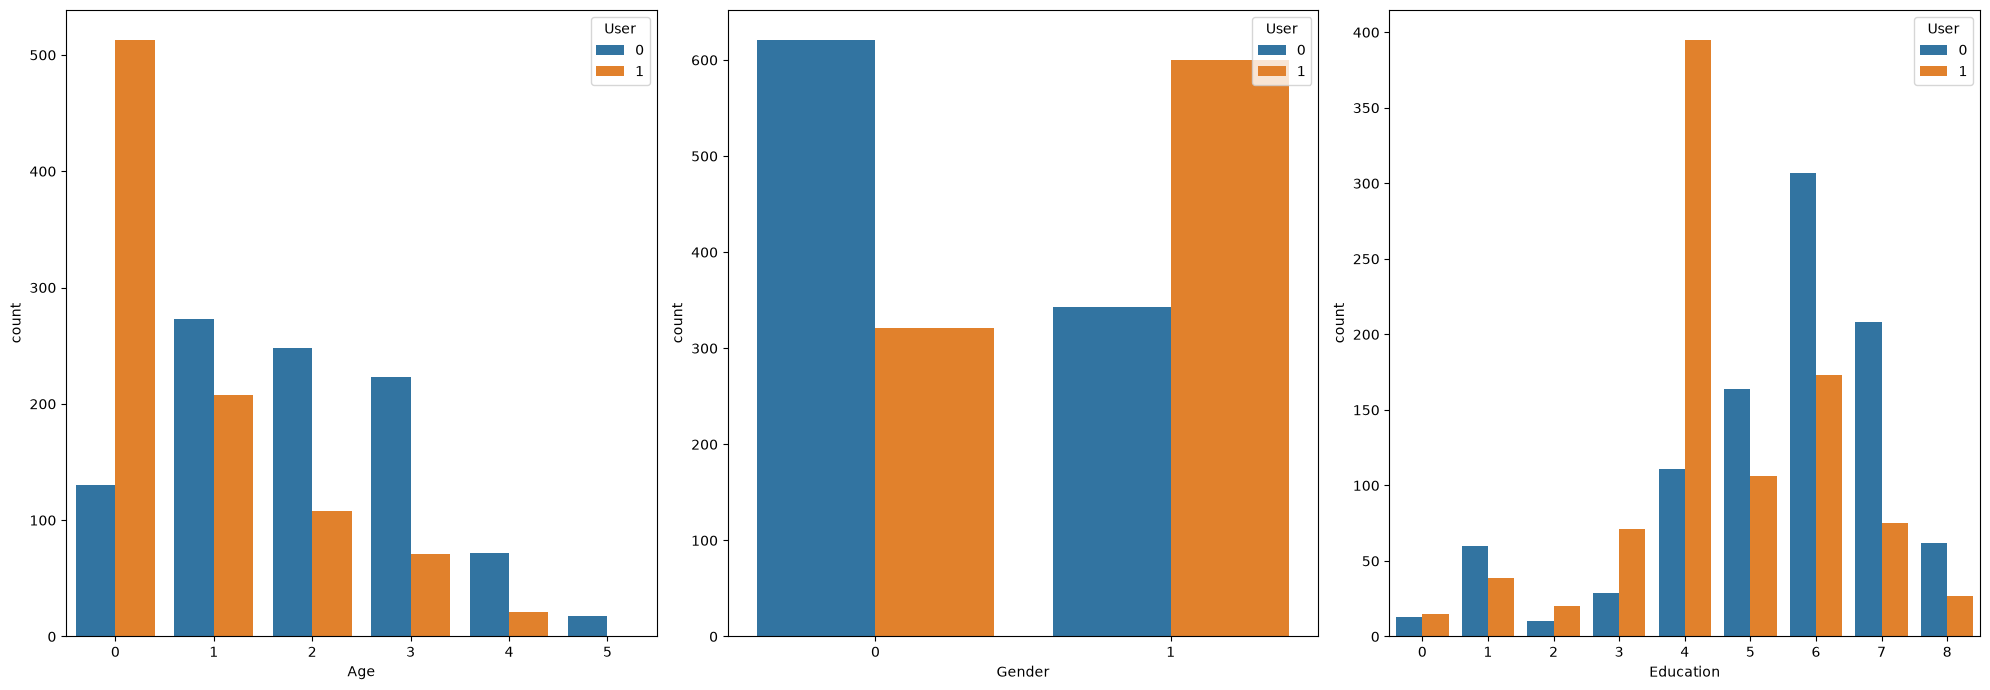

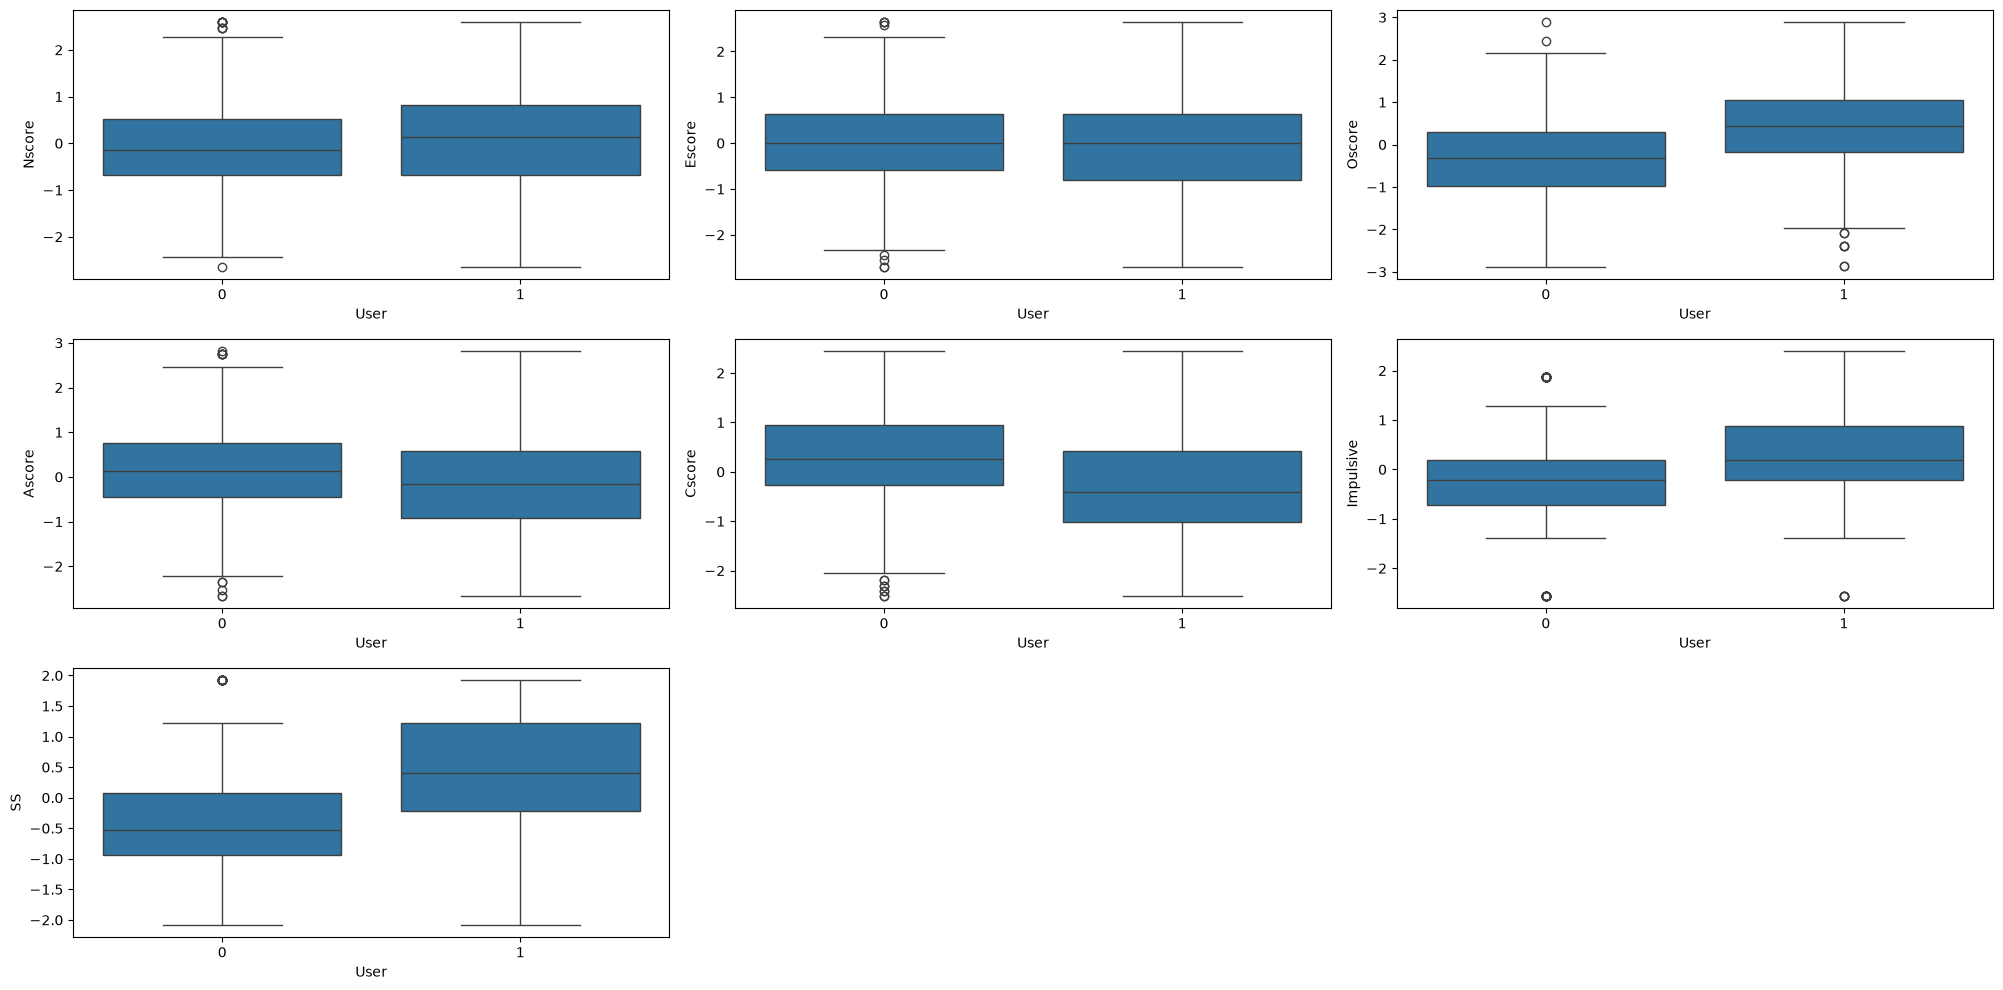

In [7]:
from pandas.core.arrays import categorical
# 1. Categorical Features vs Target
categorical_features = [
    'Age', 'Gender', 'Education'
]

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
axes = axes.flatten()
for i, col in enumerate(categorical_features):
  sns.countplot(data=df, x=col, hue="User", ax=axes[i])
  axes[i].legend(title="User", loc="upper right")
plt.tight_layout()
plt.show()

# 2. Numerical Features vs Target
numerical_features = [
    'Nscore', 'Escore', 'Oscore',
    'Ascore', 'Cscore', 'Impulsive', 'SS'
]

fig, axes = plt.subplots(3, 3, figsize=(20, 10))
axes = axes.flatten()
for i, col in enumerate(numerical_features):
  sns.boxplot(data=df, x="User", y=col, ax=axes[i])
for i in range(7, 9):
  fig.delaxes(axes[i])
plt.tight_layout()
plt.show()

**STUDENT COMMENTS & INSIGHTS (Step 1.2):**

**Đặc trưng phân loại:**
- Age: có mối liên hệ rõ rệt với biến `User`, trong đó nhóm tuổi trẻ nhất có số lượng User vượt trội so với Non-user, trong khi ở các nhóm tuổi lớn hơn, Non-user chiếm ưu thế.
- Gender: Nhóm Gender = 1 có nhiều User hơn Non-User một cách đáng kể, trong khi nhóm Gender = 0 thì lại phản ánh Non-User nhiều hơn User một cách đáng kể. Điều này cho thấy tỷ lệ User khác biệt đáng kể giữa hai nhóm giới tính.
- Education: Nhóm Education = 4 có số lượng User nhiều hơn một cách áp đảo so với Non-User. Ngược lại, các nhóm Education = 6, 7 và 8 có số lượng Non-User lớn hơn User, gợi ý rằng trình độ học vấn có mối liên hệ với biến mục tiêu.

**Đặc trưng số:**
- **Openness (Oscore):** Nhóm User có median cao hơn rõ rệt so với Non-user, cho thấy người sử dụng chất có xu hướng cởi mở với trải nghiệm mới hơn.
- **Impulsivity:** Nhóm User có median cao hơn Non-user, đồng thời khoảng tứ phân vị (IQR) dịch chuyển về phía giá trị cao hơn, cho thấy xu hướng bốc đồng có liên hệ với hành vi sử dụng chất.
- **Sensation Seeking (SS):** Có sự khác biệt nổi bật giữa median của hai nhóm. Điều này cho thấy người có xu hướng tìm kiếm cảm giác mạnh thường xuất hiện nhiều hơn trong nhóm User.
- **Neuroticism (Nscore):** Nhóm User có median cao hơn nhẹ so với Non-user, tuy nhiên phân phối hai nhóm chồng lấn đáng kể nên mức độ khác biệt không quá rõ rệt.
- **Extraversion (Escore):** Median của cả hai nhóm đều gần 0 và IQR tương đối giống nhau, cho thấy đặc trưng này ít thể hiện sự khác biệt giữa User và Non-user.
- **Agreeableness (Ascore):** Nhóm User có median thấp hơn Non-user, cho thấy xu hướng điểm Agreeableness thấp hơn ở nhóm sử dụng chất.
- **Conscientiousness (Cscore):** Nhóm User có median thấp hơn đáng kể so với Non-user cho thấy người sử dụng chất có xu hướng đạt điểm Conscientiousness thấp hơn.

**Nhận xét chung:** Oscore, Cscore và SS thể hiện sự khác biệt về median tương đối rõ rệt giữa hai nhóm User và Non-user, tiếp theo là Impulsivity và Ascore. Nscore có khác biệt nhẹ, trong khi Escore gần như tương đồng. Nhìn chung, các đặc điểm tính cách và yếu tố nhân khẩu học có mối liên hệ với hành vi sử dụng các chất thuộc Ecstasy pleiad. Tuy nhiên, các phân phối vẫn có sự chồng lấn đáng kể, cho thấy không có đặc trưng đơn lẻ nào đủ để phân biệt hoàn toàn hai nhóm.

#### STUDENT TASK 1.3: CORRELATION ANALYSIS
*Generate a correlation matrix heatmap and identify top correlated attributes.*

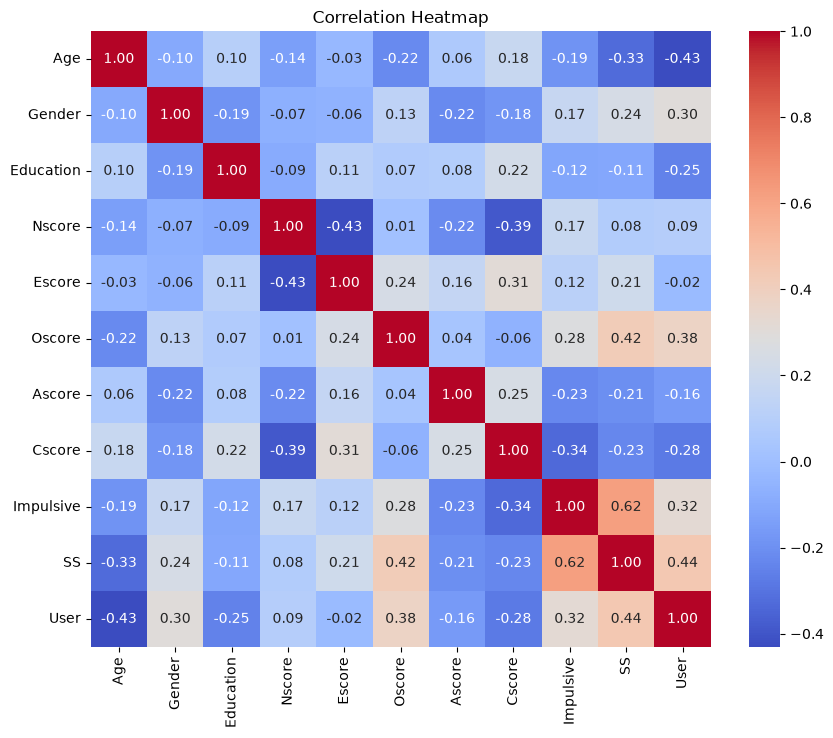

Top correlated attributes with User:


SS           0.441983
Age         -0.430927
Oscore       0.376475
Impulsive    0.320141
Gender       0.295580
Cscore      -0.278963
Education   -0.249354
Ascore      -0.161385
Nscore       0.091038
Escore      -0.020353
Name: User, dtype: float64

In [8]:
# TODO: [STUDENTS FILL IN CODE HERE]

features = [
    'Age', 'Gender', 'Education',
    'Nscore', 'Escore', 'Oscore',
    'Ascore', 'Cscore', 'Impulsive', 'SS', 'User'
]

plt.figure(figsize=(10, 8))
correlation_matrix = df[features].corr()
sns.heatmap(data=correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

# Identify top correlated attributes with User
target_corr = correlation_matrix['User'].drop('User')
top_corr_idx = np.argsort(np.abs(target_corr))[::-1]
print("Top correlated attributes with User:")
target_corr.iloc[top_corr_idx]

### STUDENT COMMENTS & KEY BUSINESS TAKEAWAYS (Step 1.3)

**1. Top Positive Correlations (Tương quan dương mạnh nhất):**

- **SS (r = 0.442):** Có tương quan dương cao nhất với biến mục tiêu User. Điều này cho thấy những người có xu hướng tìm kiếm cảm giác mạnh cao có khả năng thuộc nhóm User lớn hơn.
- **Oscore (r = 0.376):** Có tương quan dương với User, cho thấy những người có tính cách cởi mở và thích trải nghiệm mới có xu hướng thuộc nhóm User nhiều hơn.
- **Impulsive (r = 0.320):** Có tương quan dương với User, cho thấy những người có mức độ bốc đồng cao có xu hướng thuộc nhóm User nhiều hơn.

**2. Top Negative Correlations (Tương quan âm mạnh nhất):**

- **Age (r = -0.431):** Có tương quan âm lớn nhất với biến mục tiêu User. Điều này cho thấy nhóm người trẻ tuổi có xu hướng sử dụng ít nhất một chất thuộc danh sách nghiên cứu trong tháng gần nhất nhiều hơn so với các nhóm tuổi lớn hơn.
- **Cscore (r = -0.279):** Có tương quan âm với User, cho thấy những người có tính tận tâm và khả năng tự kiểm soát cao có xu hướng ít thuộc nhóm User hơn.
- **Education (r = -0.249):** Có tương quan âm với User theo cách mã hóa hiện tại, gợi ý rằng trình độ học vấn có thể liên quan đến hành vi sử dụng chất.

**3. Multicollinearity Check (Kiểm tra đa cộng tuyến):**

- Dựa trên Correlation Heatmap, không có cặp đặc trưng đầu vào nào có hệ số tương quan tuyệt đối vượt ngưỡng 0.8.
- Cặp **Impulsive và SS** có tương quan dương cao nhất (r ≈ 0.62), nhưng vẫn thấp hơn ngưỡng 0.8.
- Các cặp đặc trưng khác có mức tương quan thấp hoặc trung bình, chẳng hạn Nscore và Escore (r ≈ -0.43), Oscore và SS (r ≈ 0.42).
- Vì vậy, chưa phát hiện dấu hiệu đa cộng tuyến nghiêm trọng dựa trên ma trận tương quan Pearson. Các đặc trưng có thể được tiếp tục sử dụng trong quá trình xây dựng mô hình.

**4. Kết luận:**

Các kết quả cho thấy **SS, Age, Oscore và Impulsive** là những đặc trưng có mối liên hệ tuyến tính đáng chú ý nhất với biến mục tiêu User.

Điều này gợi ý rằng độ tuổi và các đặc điểm tâm lý, đặc biệt là xu hướng tìm kiếm cảm giác mạnh, sự cởi mở và tính bốc đồng, có thể đóng vai trò quan trọng trong việc dự đoán hành vi sử dụng chất.

Tuy nhiên, tương quan không chứng minh quan hệ nhân quả và không trực tiếp phản ánh mức độ quan trọng của đặc trưng trong mô hình Machine Learning.

# PART 2: FEATURE ENGINEERING & PREPARATION [3.0 POINTS]

### Key Guidelines:
1. **Categorical Encoding:** Convert text/categorical variables into numerical representations (One-Hot, Label Encoding).
2. **Feature Scaling:** Scale numerical features to a uniform range (StandardScaler / MinMaxScaler).
3. **Feature Selection / Creation:** Drop non-informative features or derive new meaningful features.
4. **Train-Test Split:** Divide the dataset into training and testing sets.

---

#### STUDENT TASK 2.1: CATEGORICAL ENCODING & FEATURE SCALING

In [9]:
# TODO: [STUDENTS FILL IN CODE HERE]
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler, MinMaxScaler

# 1. Select features
features = [
    'Age', 'Gender', 'Education',
    'Nscore', 'Escore', 'Oscore',
    'Ascore', 'Cscore', 'Impulsive', 'SS'
]

# 2. One-Hot Encoding
df_encoded = pd.get_dummies(
    df[features + ['User']],
    columns=['Age', 'Education'],
    drop_first=True,
    dtype=np.int8
)

display(df_encoded.head())

,Gender,Nscore,Escore,Oscore,Ascore,Cscore,Impulsive,SS,User,Age_1,...,Age_4,Age_5,Education_1,Education_2,Education_3,Education_4,Education_5,Education_6,Education_7,Education_8
0,0,0.31287,-0.57545,-0.58331,-0.91699,-0.00665,-0.21712,-1.18084,0,0,...,0,0,0,0,0,0,1,0,0,0
1,1,-0.67825,1.93886,1.43533,0.76096,-0.14277,-0.71126,-0.21575,1,1,...,0,0,0,0,0,0,0,0,0,1
2,1,-0.46725,0.80523,-0.84732,-1.62090,-1.01450,-1.37983,0.40148,0,0,...,0,0,0,0,0,0,1,0,0,0
3,0,-0.14882,-0.80615,-0.01928,0.59042,0.58489,-1.37983,-1.18084,0,0,...,0,0,0,0,0,0,0,0,1,0
4,0,0.73545,-1.63340,-0.45174,-0.30172,1.30612,-0.21712,-0.21575,0,0,...,0,0,0,0,0,0,0,0,0,1


 **STUDENT COMMENTS & RATIONALE (Step 2.1):**

**1. Encoding Method Selected (Phương pháp mã hóa):**

- Nhóm sử dụng **One-Hot Encoding** cho hai đặc trưng Age và Education vì đây là các biến phân loại đã được mã hóa bằng số. One-Hot Encoding giúp biểu diễn từng nhóm bằng các cột nhị phân (0 và 1), tránh việc mô hình hiểu nhầm các giá trị mã hóa là khoảng cách số học.
- Gender là biến phân loại nhị phân đã được mã hóa bằng số nên được giữ nguyên.

**2. Scaling Technique Selected (Phương pháp chuẩn hóa):**

- Nhóm lựa chọn **StandardScaler** để chuẩn hóa 7 đặc trưng tâm lý: Nscore, Escore, Oscore, Ascore, Cscore, Impulsive và SS.
- StandardScaler đưa các đặc trưng về thang đo có trung bình bằng 0 và độ lệch chuẩn bằng 1, giúp các đặc trưng có thang đo khác nhau không chi phối mô hình chỉ vì độ lớn giá trị.
- So với MinMaxScaler, StandardScaler không giới hạn dữ liệu trong khoảng [0, 1]. Tuy nhiên, cả hai phương pháp đều nhạy cảm với giá trị ngoại lai, dù vậy các giá trị outliers cũng không đến mức cực kì nghiêm trọng.

#### STUDENT TASK 2.2: TRAIN-TEST SPLIT & FEATURE SELECTION

In [10]:
# TODO: [STUDENTS FILL IN CODE HERE]
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Separate Features (X) and Target (y)
X = df_encoded[[
  'Gender', 'Age_1', 'Age_2', 'Age_3', 'Age_4', 'Age_5',
  'Education_1', 'Education_2', 'Education_3', 'Education_4',
  'Education_5', 'Education_6', 'Education_7', 'Education_8',
  'Nscore', 'Escore', 'Oscore', 'Ascore', 'Cscore', 'Impulsive', 'SS'
]]
y = df_encoded['User']

# 2. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Feature Scaling
num_cols = [
    'Nscore', 'Escore', 'Oscore',
    'Ascore', 'Cscore', 'Impulsive', 'SS'
]

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

X_train shape: (1508, 21), X_test shape: (377, 21)


 **STUDENT COMMENTS (Step 2.2):**

**Split Ratio (Tỷ lệ chia dữ liệu):**

- Nhóm chia dữ liệu theo tỷ lệ 80% cho tập huấn luyện (Train) và 20% cho tập kiểm tra (Test).
- Tập Train được sử dụng để huấn luyện mô hình, trong khi tập Test dùng để đánh giá khả năng dự đoán trên dữ liệu chưa từng được sử dụng để huấn luyện.
- `random_state=42` giúp đảm bảo kết quả chia dữ liệu có thể tái lập.

**Stratification (Phân chia dữ liệu theo tỷ lệ lớp):**

- Nhóm sử dụng `stratify=y` nhằm duy trì tỷ lệ User và Non-user tương đối giống nhau giữa hai tập Train và Test.
- Mặc dù dữ liệu tương đối cân bằng (48,86% User và 51,14% Non-user), stratification vẫn giúp hạn chế sai lệch phân bố lớp khi chia dữ liệu.

# PART 3: MODEL BUILDING & EVALUATION [3.0 POINTS]

### Key Guidelines:
1. **Baseline Model:** Implement a simple baseline algorithm (e.g., Logistic Regression / Linear Regression).
2. **Advanced Models:** Train at least 1–2 comparison algorithms (e.g., Decision Tree, Random Forest, XGBoost).
3. **Performance Metrics:** Evaluate models using appropriate metrics (Accuracy, Precision, Recall, F1-Score, ROC-AUC for classification; RMSE, MAE, R² for regression).
4. **Visualization:** Plot Confusion Matrix and ROC Curve (or Residual plots).

---

# #### STUDENT TASK 3.1: MODEL TRAINING & HYPERPARAMETER TUNING

In [11]:
# TODO: [STUDENTS FILL IN CODE HERE]
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 1. Initialize Models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42)
}

# 2. Train Models and Collect Metrics
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)
display(results_df)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.782493,0.831169,0.695652,0.757396,0.870523
1,Decision Tree,0.697613,0.705882,0.652174,0.677966,0.696553
2,Random Forest,0.771883,0.810127,0.695652,0.748538,0.853810


#### STUDENT TASK 3.2: MODEL COMPARISON & VISUALIZATION

Best Performing Model: Logistic Regression


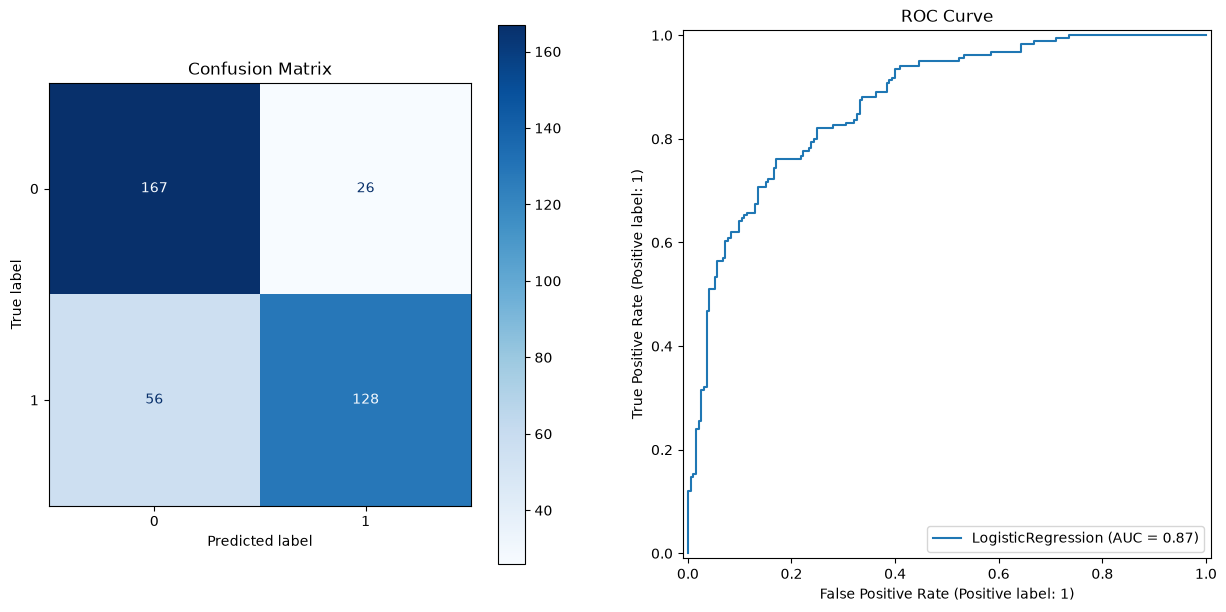

In [12]:
# TODO: [STUDENTS FILL IN CODE HERE]
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

# 1. Plot Confusion Matrix for Best Model
best_model_name = results_df.loc[results_df["F1-Score"].idxmax(), "Model"]
best_model = models[best_model_name]

print("Best Performing Model:", best_model_name)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
axes = axes.flatten()
ConfusionMatrixDisplay.from_estimator(
    best_model, X_test, y_test, cmap='Blues', ax=axes[0]
)
axes[0].set_title('Confusion Matrix')

# 2. Plot ROC Curve
RocCurveDisplay.from_estimator(best_model, X_test, y_test, ax=axes[1])
plt.title('ROC Curve')
plt.show()

### STUDENT COMMENTS & MODEL EVALUATION (Step 3.2)

**1. Best Performing Model (Mô hình tốt nhất):**

- Trong ba mô hình được thử nghiệm gồm Logistic Regression, Decision Tree và Random Forest, **Logistic Regression** đạt F1-Score cao nhất (**0.7574**), đồng thời có Accuracy cao nhất (**78,25%**) và ROC-AUC cao nhất (**0.8705**).
- Random Forest có hiệu suất tương đối gần Logistic Regression, với F1-Score = **0.7485** và ROC-AUC = **0.8538**. Trong khi đó, Decision Tree có kết quả thấp hơn, với F1-Score = **0.6780** và ROC-AUC = **0.6966**.
- Dựa trên F1-Score, nhóm tạm thời lựa chọn **Logistic Regression là mô hình tốt nhất** trong ba mô hình trên tập Test hiện tại.
- Tuy nhiên, sự chênh lệch hiệu suất giữa Logistic Regression và Random Forest tương đối nhỏ. Do đó, kết quả lựa chọn mô hình cần được kiểm chứng thêm thông qua Cross-Validation và Hyperparameter Tuning trong Ongoing 3 để đánh giá tính ổn định và khả năng tổng quát hóa.

**2. Key Metric Comparison (So sánh các chỉ số):**

Nhóm sử dụng **F1-Score** làm tiêu chí đánh giá chính vì đây là trung bình điều hòa giữa Precision và Recall, giúp đánh giá sự cân bằng giữa khả năng dự đoán chính xác nhóm User và khả năng phát hiện những User thực tế.

Kết quả đánh giá ba mô hình trên tập Test:

| Model | Accuracy | Precision | Recall | F1-Score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | 0.7825 | 0.8312 | 0.6957 | 0.7574 | 0.8705 |
| Decision Tree | 0.6976 | 0.7059 | 0.6522 | 0.6780 | 0.6966 |
| Random Forest | 0.7719 | 0.8101 | 0.6957 | 0.7485 | 0.8538 |

**Nhận xét:**

- **Precision (83,12%):** Trong số những người được Logistic Regression dự đoán là User, có 83,12% thực sự thuộc nhóm User.
- **Recall (69,57%):** Mô hình phát hiện đúng 69,57% tổng số User thực tế, cho thấy vẫn còn một tỷ lệ đáng kể User bị bỏ sót.
- **F1-Score (0.7574):** Logistic Regression đạt mức cân bằng giữa Precision và Recall tốt nhất trong ba mô hình được thử nghiệm.
- **ROC-AUC (0.8705):** Cho thấy Logistic Regression có khả năng phân biệt tương đối tốt giữa hai nhóm User và Non-User khi xét trên nhiều ngưỡng phân loại khác nhau.
- So với Decision Tree, Logistic Regression vượt trội ở tất cả các chỉ số đánh giá. Trong khi đó, Logistic Regression và Random Forest có Recall bằng nhau (0.6957), nhưng Logistic Regression đạt Precision và F1-Score cao hơn.

**3. Trade-offs / Error Analysis (Phân tích sai số):**

Dựa trên Confusion Matrix của Logistic Regression trên **377 quan sát thuộc tập Test**:

- **True Positive (TP = 128):** Mô hình dự đoán chính xác 128 trường hợp thực tế thuộc nhóm User.
- **True Negative (TN = 167):** Mô hình dự đoán chính xác 167 trường hợp thực tế thuộc nhóm Non-User.
- **False Positive (FP = 26):** Có 26 trường hợp thực tế là Non-User nhưng bị dự đoán thành User, tương đương **13,47% tổng số Non-User thực tế**. Việc phân loại sai này có thể dẫn đến đánh giá không chính xác tình trạng sử dụng chất và gây nguy cơ gán nhãn hoặc kỳ thị cá nhân nếu kết quả được sử dụng không phù hợp.
- **False Negative (FN = 56):** Có 56 trường hợp thực tế là User nhưng bị dự đoán thành Non-User, tương đương **30,43% tổng số User thực tế**. Điều này cho thấy mô hình vẫn bỏ sót một tỷ lệ đáng kể những người thuộc nhóm User.

**Trade-off giữa Precision và Recall:**

- Nếu mục tiêu ứng dụng là hỗ trợ sàng lọc nhằm cung cấp các chương trình giáo dục hoặc phòng ngừa tự nguyện, việc giảm False Negative có thể được ưu tiên để hạn chế bỏ sót đối tượng cần hỗ trợ.
- Tuy nhiên, việc giảm ngưỡng phân loại nhằm tăng Recall thường có thể làm tăng False Positive và giảm Precision.
- Vì vậy, cần cân nhắc giữa khả năng phát hiện User và nguy cơ phân loại nhầm Non-User, đặc biệt khi nghiên cứu liên quan đến thông tin cá nhân nhạy cảm.

**Kết luận:**

Logistic Regression đạt hiệu suất tốt nhất trong ba mô hình baseline trên tập Test hiện tại, với F1-Score = **0.7574** và ROC-AUC = **0.8705**. Tuy nhiên, Recall chỉ đạt 69,57%, cho thấy mô hình vẫn bỏ sót khoảng 30,43% số User thực tế.

Do đó, Logistic Regression được lựa chọn làm mô hình baseline tốt nhất ở giai đoạn Ongoing 2. Trong Ongoing 3, nhóm sẽ tiếp tục sử dụng Cross-Validation, Hyperparameter Tuning và xem xét điều chỉnh Classification Threshold trên dữ liệu validation nhằm cải thiện hiệu suất, đặc biệt là Recall, đồng thời kiểm soát Precision và F1-Score.

# PART 4: DISCUSSION, CONCLUSION & RECOMMENDATIONS [1.0 POINT]

### Key Guidelines:
1. **Summary of Findings:** Reiterate key insights discovered from modeling and EDA.
2. **Business Recommendations:** Translate model results into actionable strategies.
3. **Future Work / Model Deployment Plan:** Suggest future improvements for full project completion.

---

ư## STUDENT TASK 4.1: CONCLUSION & ACTIONABLE BUSINESS RECOMMENDATIONS

### 1. Core Findings & Model Summary (Kết quả chính và tổng kết mô hình)

- Nghiên cứu sử dụng **1.885 quan sát** nhằm xây dựng mô hình phân loại trạng thái sử dụng ít nhất một trong tám chất được lựa chọn thuộc nhóm Ecstasy pleiad trong tháng gần nhất, dựa trên các đặc điểm nhân khẩu học và tâm lý.
- Biến mục tiêu `User` có phân phối tương đối cân bằng, với **48,86% User** và **51,14% Non-User**, giúp hai lớp có mức độ đại diện khá đồng đều trong tập dữ liệu.
- Kết quả EDA và Correlation Analysis cho thấy các đặc trưng tâm lý như **Sensation Seeking (r = 0.442)**, **Openness (r = 0.376)** và **Impulsivity (r = 0.320)** có tương quan dương đáng chú ý với biến mục tiêu. Ngược lại, **Age (r = -0.431)** và **Conscientiousness (r ≈ -0.279)** có tương quan âm. Điều này gợi ý rằng độ tuổi và các đặc điểm tâm lý có thể cung cấp thông tin hữu ích cho bài toán phân loại hành vi sử dụng chất.
- Nhóm đã thử nghiệm ba mô hình gồm Logistic Regression, Decision Tree và Random Forest. Dựa trên kết quả đánh giá trên tập Test, **Logistic Regression** được lựa chọn làm mô hình tốt nhất với **Accuracy = 78,25%, F1-Score = 0.7574 và ROC-AUC = 0.8705**.
- Tuy nhiên, Recall của Logistic Regression chỉ đạt **69,57%**, tương ứng với việc mô hình bỏ sót 56 trong tổng số 184 User thực tế trên tập Test. Điều này cho thấy mô hình vẫn có những hạn chế cần cải thiện trước khi xem xét bất kỳ ứng dụng thực tế nào.

### 2. Actionable Business Recommendations (Đề xuất ứng dụng thực tế)

**Recommendation 1: Nghiên cứu các yếu tố liên quan đến hành vi sử dụng chất**

- Ưu tiên nghiên cứu sâu hơn các đặc điểm tâm lý có tương quan đáng chú ý với User, đặc biệt là Sensation Seeking, Impulsivity và Openness, nhằm hiểu rõ mối liên hệ giữa tính cách và hành vi sử dụng chất.
- Sử dụng các kết quả phân tích ở cấp độ tổng hợp để xác định những chủ đề cần được chú trọng trong hoạt động giáo dục và truyền thông, chẳng hạn như hành vi tìm kiếm cảm giác mạnh, bốc đồng,...
- Các mối tương quan chỉ phản ánh sự liên hệ, không đủ bằng chứng để khẳng định những đặc điểm tâm lý này là nguyên nhân trực tiếp dẫn đến hành vi sử dụng chất.

**Recommendation 2: Hỗ trợ thiết kế các chương trình giáo dục và phòng ngừa**

- Kết quả EDA cho thấy nhóm tuổi trẻ có xu hướng thuộc nhóm User nhiều hơn. Vì vậy, có thể ưu tiên nghiên cứu nhu cầu giáo dục và nâng cao nhận thức của nhóm người trẻ, chẳng hạn thông qua các chương trình truyền thông trong trường học, đại học hoặc cộng đồng.
- Nội dung chương trình có thể tập trung vào tác động của việc sử dụng chất, kỹ năng ra quyết định, khả năng kiểm soát hành vi và cách tiếp cận các nguồn hỗ trợ đáng tin cậy.
- Đánh giá hiệu quả chương trình bằng các khảo sát trước và sau hoạt động, đo lường sự thay đổi về kiến thức, nhận thức rủi ro và mức độ tiếp cận thông tin.
- Việc lựa chọn đối tượng tham gia nên dựa trên nhu cầu thực tế và nguyên tắc tự nguyện, không gán nhãn hoặc kỳ thị cá nhân dựa trên đặc điểm tâm lý hay kết quả dự đoán.

**Recommendation 3: Phát triển công cụ hỗ trợ nghiên cứu và phân tích dữ liệu**

- Có thể phát triển một công cụ phân tích sử dụng Logistic Regression nhằm minh họa mối liên hệ giữa các đặc điểm đầu vào và xác suất dự đoán thuộc nhóm User trong phạm vi dữ liệu nghiên cứu.
- Công cụ nên tập trung vào phân tích thống kê, trực quan hóa dữ liệu và đánh giá hiệu suất mô hình, thay vì sử dụng kết quả dự đoán để xác định tình trạng sử dụng chất của từng cá nhân.
- Trước khi xem xét áp dụng ngoài phạm vi nghiên cứu, cần kiểm tra khả năng tổng quát hóa, độ tin cậy của xác suất dự đoán và những rủi ro liên quan đến quyền riêng tư, thiên lệch dữ liệu và việc phân loại sai.

### 3. Future Improvements & Limitations (Hạn chế và hướng phát triển)

**Bổ sung và đa dạng hóa dữ liệu:**

- Thu thập thêm các yếu tố như môi trường sống, điều kiện kinh tế, ảnh hưởng từ bạn bè và hoàn cảnh gia đình để nghiên cứu những mối liên hệ mà bộ dữ liệu hiện tại chưa phản ánh đầy đủ.
- Mở rộng kích thước mẫu và tăng mức độ đa dạng về quốc gia, sắc tộc và nhóm tuổi nhằm cải thiện tính đại diện và khả năng khái quát hóa của kết quả.

**Khắc phục hạn chế của dữ liệu:**

- Bộ dữ liệu tập trung chủ yếu ở UK và USA, đồng thời phần lớn người tham gia thuộc nhóm White. Điều này có thể hạn chế khả năng áp dụng kết quả cho các quần thể khác.
- Dữ liệu về hành vi sử dụng chất được thu thập thông qua phương pháp tự báo cáo (Self-reported Data), do đó có thể tồn tại sai lệch.
- Nghiên cứu mang tính quan sát nên chưa thể thiết lập quan hệ nhân quả giữa các đặc điểm tâm lý và hành vi sử dụng chất.

**Tối ưu hóa và đánh giá mô hình:**

- Sử dụng **GridSearchCV kết hợp Stratified K-Fold Cross-Validation** để tìm bộ siêu tham số phù hợp và đánh giá mức độ ổn định của mô hình.
- Thử nghiệm **Classification Threshold Tuning** nhằm cải thiện Recall và giảm số lượng False Negative, đồng thời kiểm soát Precision và F1-Score để hạn chế gia tăng False Positive.

**Phát triển ứng dụng minh họa:**

- Trong tương lai, có thể sử dụng **Streamlit** để xây dựng giao diện trực quan hóa dữ liệu, so sánh các mô hình và minh họa kết quả phân loại trong môi trường nghiên cứu.
- Cần đảm bảo các nguyên tắc về bảo mật, quyền riêng tư và sử dụng dữ liệu có trách nhiệm. Kết quả mô hình không nên được xem là bằng chứng xác nhận hành vi sử dụng chất hoặc sử dụng để đưa ra quyết định bất lợi đối với cá nhân.

---
## Author
**MaiCV2 - FPT University**

## Change Log
| Date (YYYY-MM-DD) | Version | Changed By | Description |
| :--- | :--- | :--- | :--- |
| 2026-08-17 | 1.0 | MaiCV2 | Create template file |

<h3 align="center"> © FPT University 2026. All rights reserved. </h3>